In [4]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import netCDF4 as nc
import os

In [16]:
df = pd.read_excel('../../Data/extendedSSPs.xlsx')
dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in ['ssp119','ssp126','ssp534-over']}

In [11]:
dfs['ssp126'].head()

quantile,mean,median,0.05,0.95
1850-07-01 00:00:00,-0.036296,-0.042477,-0.158622,0.101991
1851-07-01 00:00:00,-0.006617,-0.011424,-0.125681,0.126811
1852-07-01 00:00:00,-0.003862,-0.008641,-0.123915,0.130445
1853-07-01 00:00:00,-0.006655,-0.011269,-0.125396,0.126352
1854-07-01 00:00:00,-0.023638,-0.030521,-0.141879,0.111638


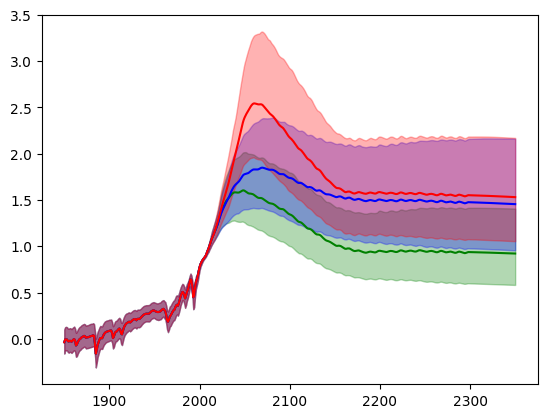

In [75]:
colors = ['green','blue','red']
for i,s in enumerate(['ssp119','ssp126','ssp534-over']):
    plt.fill_between(np.arange(1850,2351), dfs[s][0.05], dfs[s][0.95], color=colors[i],alpha=0.3)
    plt.plot(np.arange(1850,2351), dfs[s]['mean'],color=colors[i])

In [69]:
overshoots = {}
for s in ['ssp119', 'ssp126', 'ssp534-over']:
    overshoots[s] = dict(T_conv = [dfs[s][0.05][-100:].mean(), dfs[s][0.95][-100:].mean()], 
                         T_peak = [dfs[s][0.05].max(), dfs[s][0.95].max()] )
    # arr = []
    # for i,m in enumerate([0.05,0.95]):
    #     locs = np.where(np.abs())

In [70]:
overshoots['ssp534-over']

{'T_conv': [np.float64(1.0746304249805325), np.float64(2.181046920156417)],
 'T_peak': [np.float64(1.9611345023153), np.float64(3.32016735138828)]}

In [56]:
arr = dfs['ssp119'][0.05].to_numpy()
np.argmin(np.abs(arr-overshoots['ssp126']['T_conv'][0]))

np.int64(256)

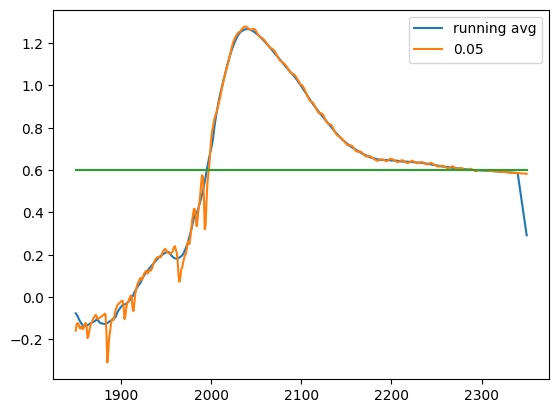

In [101]:
s='ssp119'
m=0.05
N=20
plt.plot(np.arange(1850,2351),np.convolve(dfs[s][m].to_numpy(), 
                                          np.ones(N)/N)[int(np.floor(N/2)):-int(np.floor(N/2))+1],
         label='running avg')
plt.plot(np.arange(1850,2351), dfs[s][m].to_numpy(),label=m)
plt.plot([1850,2350], [overshoots[s]['T_conv'][0]]*2)
plt.legend()

In [95]:
round(N/2)

2

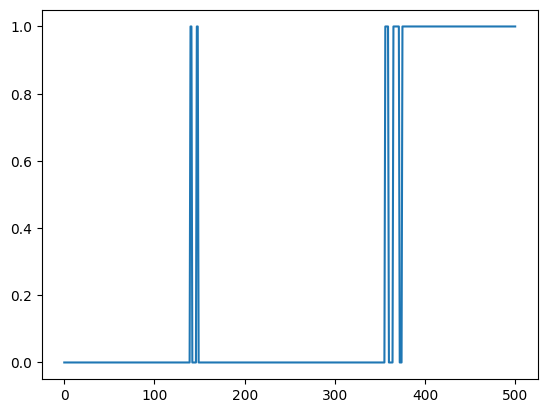

In [68]:
s = 'ssp119'
m = [0.05, 0]
plt.plot((np.abs((dfs[s][m[0]].to_numpy()-overshoots[s]['T_conv'][m[1]]))<=0.05))

In [41]:
np.where(np.abs(arr-overshoots['ssp126']['T_conv'][0])<=0.1)[0]

array([156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 321, 322,
       323, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339,
       340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352,
       353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365,
       366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378,
       379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391,
       392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404,
       405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417,
       418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430,
       431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443,
       444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456,
       457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469,
       470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482,
       483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 49

# Reading .nc files for the 10 scenarios

In [9]:
folder = '../../Data/Schwaab 2024/fair_100_mesmer_10_quantiles_tar/'
scenarios = os.listdir(folder)
ds_scens = {s[:-3]: nc.Dataset(folder+s) for s in scenarios}

In [10]:
print(scenarios)

['Ref_1p5.nc', 'Ren.nc', 'ModAct.nc', 'SP.nc', 'CurPol.nc', 'LD.nc', 'GS.nc', 'ssp534-over.nc', 'ssp119.nc', 'Neg.nc']


In [33]:
print(ds_scens['ssp119'].year)

AttributeError: NetCDF: Attribute not found

In [34]:
import xarray as xr

In [36]:
ds_scens = {s[:-3]: xr.open_dataset(folder+s) for s in scenarios}

In [69]:
arr = ds_scens['ssp534-over']

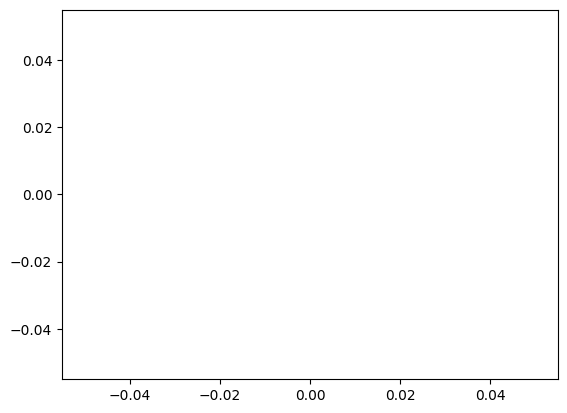

In [83]:
plt.plot(arr['tas'].sel(year=slice(1850,2100),lon=8.75,lat=-51.25,quantile=0.5))

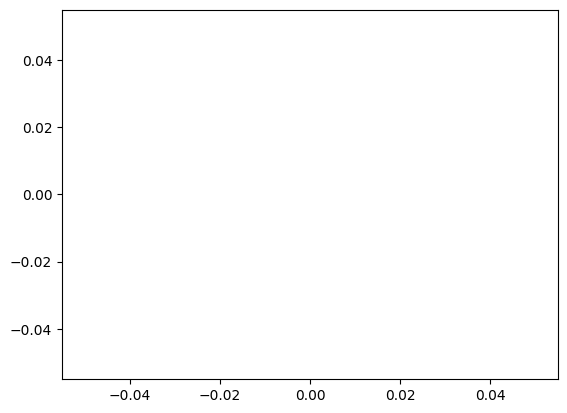

In [82]:
plt.plot(ds_scens['ssp534-over'].sel(quantile=0.5,lat=-51.25,lon=8.75).tas)

In [88]:
print(arr['tas'].sel(year=slice(1850,2100),lon=8.75,lat=-51.25,quantile=0.05).values)

[nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan na

In [107]:
ds_scens['Ref_1p5']['tas'].size

42210168

In [108]:
(~np.isnan(ds_scens['Ref_1p5']['tas'].to_numpy())).sum()/ds_scens['Ref_1p5']['tas'].size

np.float64(0.33116883116883117)